# 03 — Laser waveform (`laser_scope`)

Load the laser scope trace from every chunk: `signal` and `times`, shape `(n_shots, 2002)`, 25 ps per sample (~50 ns window).

In [1]:
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
files = sorted(DATA_DIR.glob("chunk_*.h5"))

In [2]:
signal, times = [], []
for path in files:
    with h5py.File(path, "r") as f:
        signal.append(f["laser_scope/signal"][:])
        times.append(f["laser_scope/times"][:])

signal = np.concatenate(signal)  # V
times = np.concatenate(times)    # ns

print("signal", signal.shape, "| times", times.shape)
print(f"time window {times[0, 0]:.2f} to {times[0, -1]:.2f} ns, step {times[0, 1] - times[0, 0]:.3f} ns")

signal (2100, 2002) | times (2100, 2002)
time window -4.71 to 45.31 ns, step 0.025 ns


## A few shots and the mean

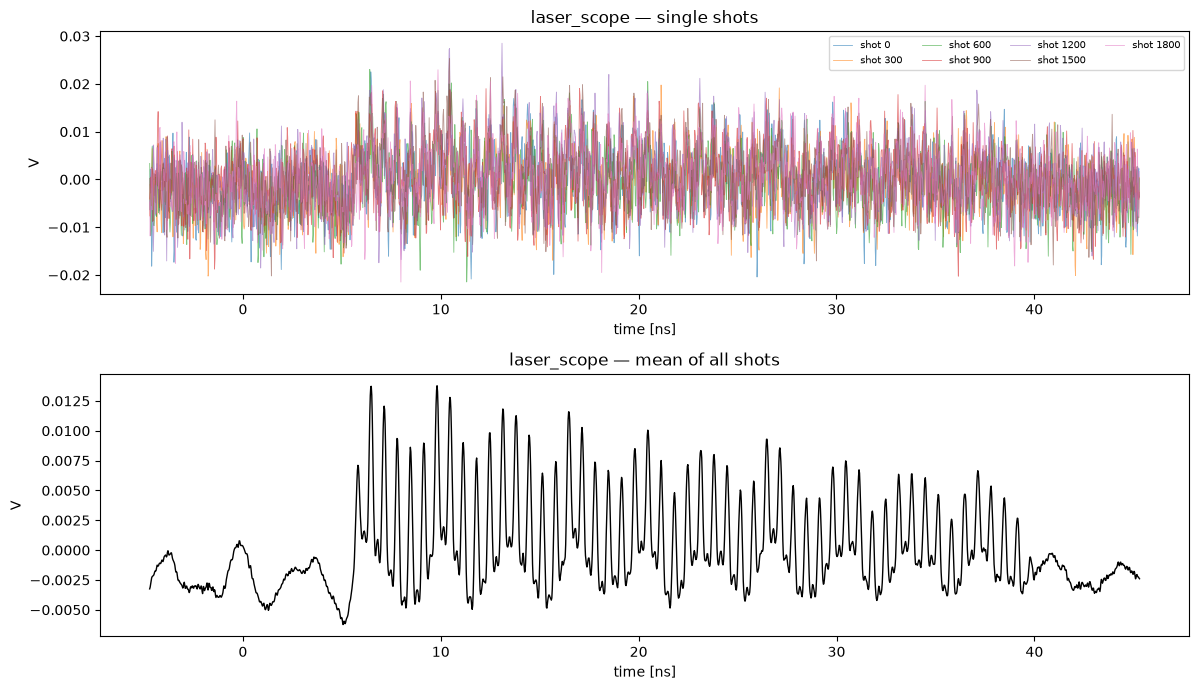

In [3]:
SHOTS = range(0, 2100, 300)

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for s in SHOTS:
    axes[0].plot(times[s], signal[s], lw=0.6, alpha=0.6, label=f"shot {s}")
axes[0].set(title="laser_scope — single shots", xlabel="time [ns]", ylabel="V")
axes[0].legend(fontsize=7, ncol=4)

axes[1].plot(times[0], signal.mean(axis=0), "k", lw=1)
axes[1].set(title="laser_scope — mean of all shots", xlabel="time [ns]", ylabel="V")
fig.tight_layout()

## All shots as an image

Each row is one shot. The time axis of each shot shifts by at most one sample (25 ps), so we use `times[0]` for all rows.

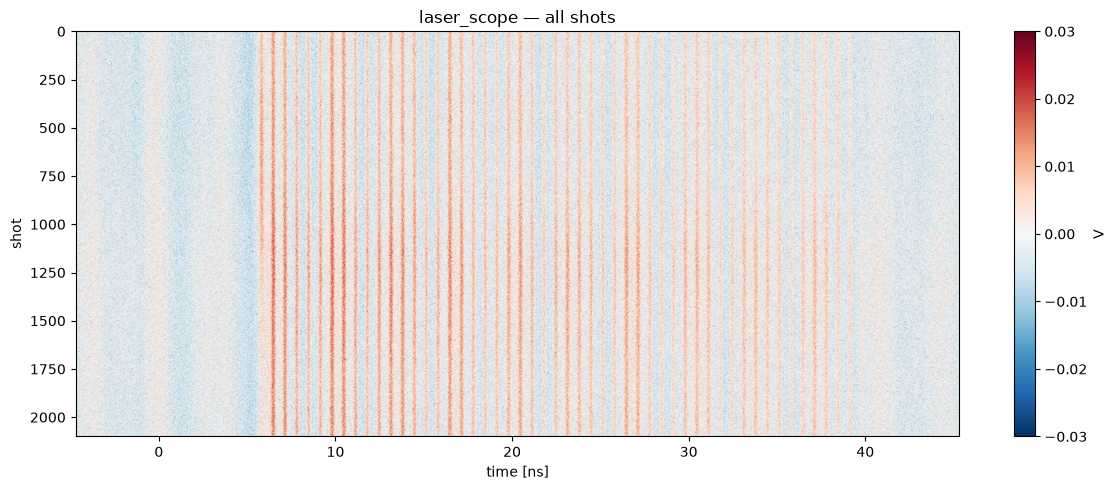

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(signal, aspect="auto", cmap="RdBu_r", vmin=-0.03, vmax=0.03,
               extent=[times[0, 0], times[0, -1], len(signal), 0])
fig.colorbar(im, ax=ax, label="V")
ax.set(title="laser_scope — all shots", xlabel="time [ns]", ylabel="shot")
fig.tight_layout()

## One laser number per shot (matched filter)

A single trace is noisy, so we compress each shot to one number: how much of the **mean pulse train** it contains.

1. subtract the baseline (mean before 5 ns)
2. take the mean trace inside the train (5.6–39.8 ns) as the template
3. `laser_amp = (shot · template) / (template · template)` → 1.0 means "like the average shot"

Using all ~50 pulses at once averages out the noise much better than looking at the peak or a single pulse.

In [5]:
TRAIN = (5.6, 39.8)  # ns
t = times[0]

clean = signal - signal[:, t < 5].mean(axis=1, keepdims=True)
template = clean.mean(axis=0) * ((t > TRAIN[0]) & (t < TRAIN[1]))
laser_amp = clean @ template / (template @ template)

# sanity check: the first and second half of the train should agree if laser_amp measures something real
half1 = template * (t <= 22)
half2 = template * (t > 22)
r_halves = np.corrcoef(clean @ half1, clean @ half2)[0, 1]
print(f"laser_amp: mean {laser_amp.mean():.2f}, std {laser_amp.std():.2f} | first vs second half of train r = {r_halves:.2f}")

laser_amp: mean 1.00, std 0.12 | first vs second half of train r = 0.87


## Laser vs BCM_GUN

Two things to keep apart:
- **slow drift**: both signals change over the run, which alone gives a high correlation
- **shot-to-shot**: after removing the slow drift (subtract a 51-shot rolling mean), do they still move together?

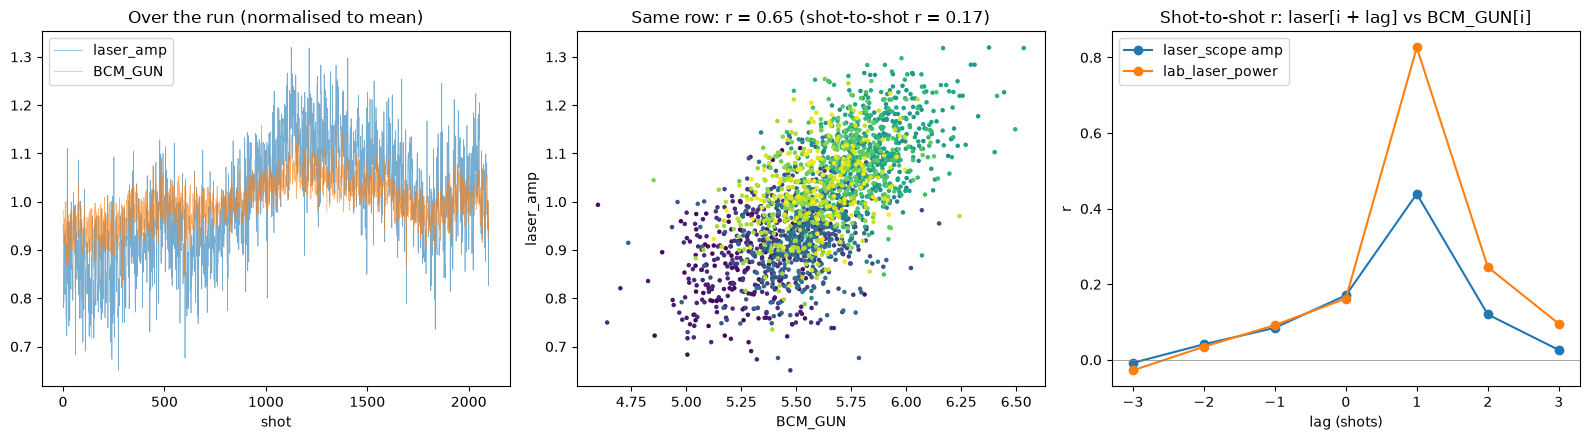

In [6]:
bcm_gun = np.concatenate([h5py.File(path, "r")["BCM_GUN"][:] for path in files])
lab_power = np.concatenate([h5py.File(path, "r")["lab_laser_power"][:] for path in files])


def detrend(x, k=51):
    padded = np.pad(x, k // 2, mode="edge")
    return x - np.convolve(padded, np.ones(k) / k, mode="valid")


def corr(x, y):
    return np.corrcoef(x, y)[0, 1]


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(laser_amp / laser_amp.mean(), lw=0.5, alpha=0.6, label="laser_amp")
axes[0].plot(bcm_gun / bcm_gun.mean(), lw=0.5, alpha=0.6, label="BCM_GUN")
axes[0].set(title="Over the run (normalised to mean)", xlabel="shot")
axes[0].legend()

axes[1].scatter(bcm_gun, laser_amp, s=5, c=np.arange(len(bcm_gun)), cmap="viridis")
axes[1].set(title=f"Same row: r = {corr(laser_amp, bcm_gun):.2f} (shot-to-shot r = {corr(detrend(laser_amp), detrend(bcm_gun)):.2f})",
            xlabel="BCM_GUN", ylabel="laser_amp")

lags = np.arange(-3, 4)
for name, x in [("laser_scope amp", laser_amp), ("lab_laser_power", lab_power)]:
    r = [corr(detrend(np.roll(x, -lag))[5:-5], detrend(bcm_gun)[5:-5]) for lag in lags]
    axes[2].plot(lags, r, "o-", label=name)
axes[2].axhline(0, color="grey", lw=0.5)
axes[2].set(title="Shot-to-shot r: laser[i + lag] vs BCM_GUN[i]", xlabel="lag (shots)", ylabel="r")
axes[2].legend()
fig.tight_layout()

**Result:** shot-to-shot, the laser matches BCM_GUN best at **lag +1**: the laser saved in row `i + 1` goes with
the charge in row `i`. One of the two is stored one shot off. Below, we line them up and redo the scatter.

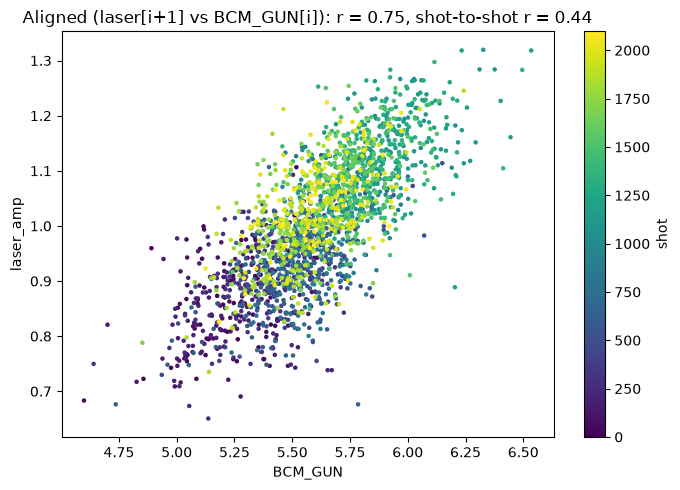

In [7]:
# pair laser[i + 1] with BCM_GUN[i]
laser_next, bcm_now = laser_amp[1:], bcm_gun[:-1]

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(bcm_now, laser_next, s=5, c=np.arange(len(bcm_now)), cmap="viridis")
fig.colorbar(sc, ax=ax, label="shot")
ax.set(title=f"Aligned (laser[i+1] vs BCM_GUN[i]): r = {corr(laser_next, bcm_now):.2f}, "
             f"shot-to-shot r = {corr(detrend(laser_next), detrend(bcm_now)):.2f}",
       xlabel="BCM_GUN", ylabel="laser_amp")
fig.tight_layout()

## Integral instead of the matched filter

Same background subtraction, then simply integrate the trace over the pulse train window (5.6–39.8 ns).

laser_int: mean 0.120 V·ns, std 0.017 | first vs second half r = 0.83
laser_int vs laser_amp: r = 0.92


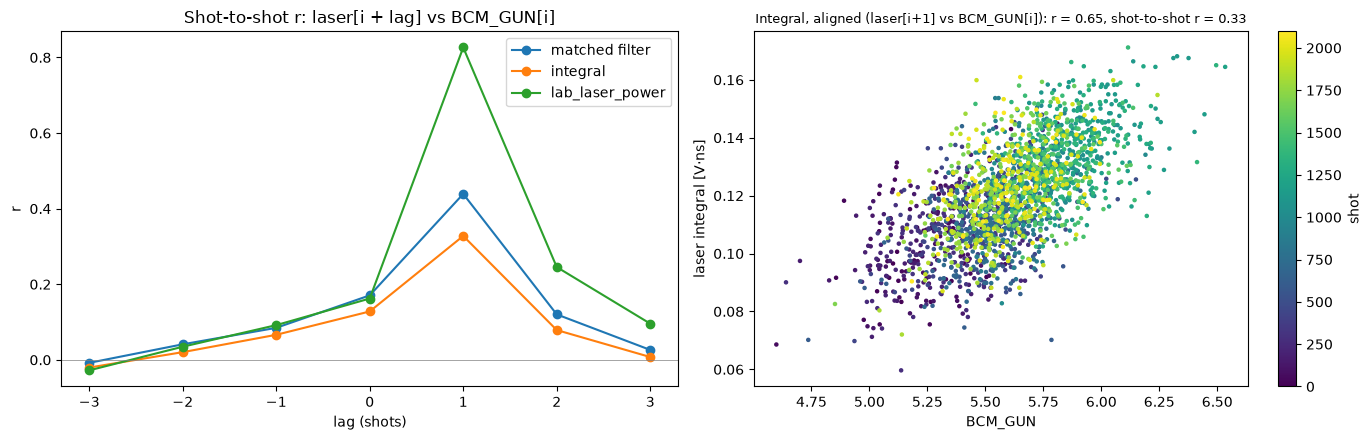

In [8]:
in_train = (t > TRAIN[0]) & (t < TRAIN[1])
dt = t[1] - t[0]
laser_int = clean[:, in_train].sum(axis=1) * dt  # V·ns

# same sanity check as before: do the two halves of the train agree?
r_halves_int = corr(clean[:, in_train & (t <= 22)].sum(axis=1), clean[:, in_train & (t > 22)].sum(axis=1))
print(f"laser_int: mean {laser_int.mean():.3f} V·ns, std {laser_int.std():.3f} | first vs second half r = {r_halves_int:.2f}")
print(f"laser_int vs laser_amp: r = {corr(laser_int, laser_amp):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for name, x in [("matched filter", laser_amp), ("integral", laser_int), ("lab_laser_power", lab_power)]:
    r = [corr(detrend(np.roll(x, -lag))[5:-5], detrend(bcm_gun)[5:-5]) for lag in lags]
    axes[0].plot(lags, r, "o-", label=name)
axes[0].axhline(0, color="grey", lw=0.5)
axes[0].set(title="Shot-to-shot r: laser[i + lag] vs BCM_GUN[i]", xlabel="lag (shots)", ylabel="r")
axes[0].legend()

sc = axes[1].scatter(bcm_gun[:-1], laser_int[1:], s=5, c=np.arange(len(bcm_gun) - 1), cmap="viridis")
fig.colorbar(sc, ax=axes[1], label="shot")
axes[1].set(title=f"Integral, aligned (laser[i+1] vs BCM_GUN[i]): r = {corr(laser_int[1:], bcm_gun[:-1]):.2f}, "
                  f"shot-to-shot r = {corr(detrend(laser_int[1:]), detrend(bcm_gun[:-1])):.2f}",
            xlabel="BCM_GUN", ylabel="laser integral [V·ns]")
axes[1].title.set_fontsize(9)
fig.tight_layout()